#Часть 0

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from mnist import load_mnist

# Загружаем данные
train, validation, test = load_mnist()

# Извлекаем картинки и метки
X_train_full, y_train_full = train
X_val, y_val = validation
X_test, y_test = test

print(f"Размер обучающей выборки: {X_train_full.shape}")
print(f"Размер валидационной выборки: {X_val.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")

Extracting MNIST-data/train-images-idx3-ubyte.gz
Extracting MNIST-data/train-labels-idx1-ubyte.gz
Extracting MNIST-data/t10k-images-idx3-ubyte.gz
Extracting MNIST-data/t10k-labels-idx1-ubyte.gz
Размер обучающей выборки: (55000, 28, 28, 1)
Размер валидационной выборки: (5000, 28, 28, 1)
Размер тестовой выборки: (10000, 28, 28, 1)


Одно изображение MNIST имеет размер 28 x 28 пикселей и один канал. Поэтому после представления каждого пикселя как отдельного признака объект имеет 28*28=784 признака.

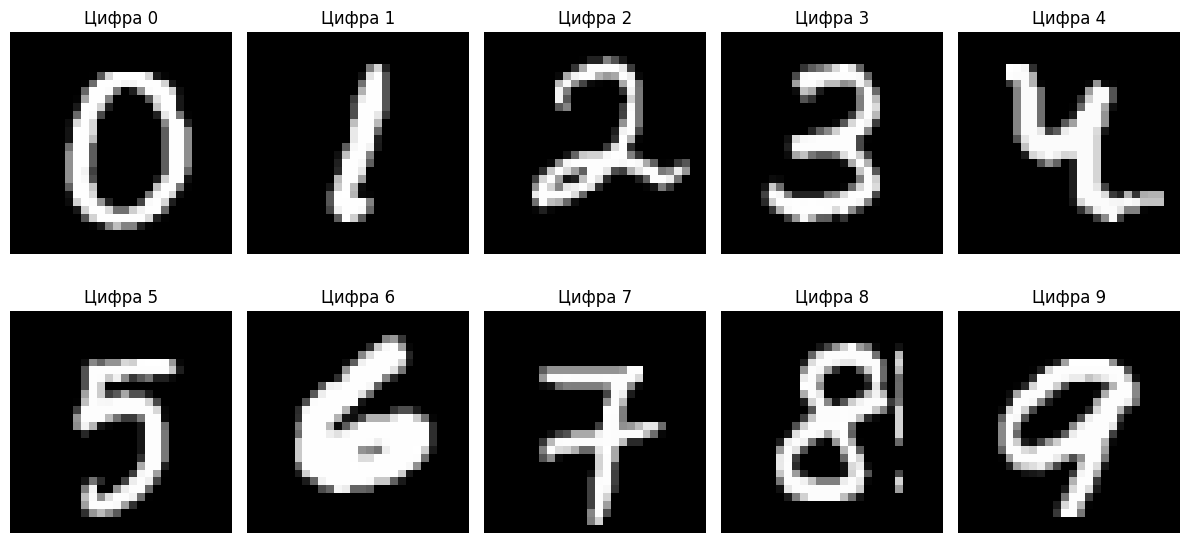

Форма X: (60000, 784)
Форма y: (60000,)
Уникальные классы: [0 1 2 3 4 5 6 7 8 9]


In [13]:
# Визуализация цифр
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
axes = axes.ravel()

for digit in range(10):
  indices = np.where(y_train_full == digit)[0]
  idx = indices[1]
  img = X_train_full[idx].reshape(28, 28)
  axes[digit].imshow(img,cmap='gray')
  axes[digit].set_title(f"Цифра {digit}")
  axes[digit].axis('off')

plt.tight_layout()
plt.show()

# Объединяем train и validation
X = np.concatenate([X_train_full, X_val],axis=0)
y = np.concatenate([y_train_full, y_val],axis=0)

# Разворачиваем изображения
X = X.reshape(X.shape[0],-1)

# Нормализация
X = X.astype(np.float32) / 255.0

print(f"Форма X: {X.shape}")
print(f"Форма y: {y.shape}")
print(f"Уникальные классы: {np.unique(y)}")

#Часть 1


часть 1.1

In [14]:
class my_PCA:
    def __init__(self, n_components=None):
        self.n_components = n_components
        self.components_ = None
        self.explained_variance_ = None
        self.mean_ = None

    def fit(self, X):
        # Среднее каждого признака
        self.mean_ = np.mean(X, axis=0)

        # Центрирование
        X_centered = X - self.mean_

        # SVD
        U, S, Vt = np.linalg.svd(X_centered,full_matrices=False)

        # Собственные значения
        explained_variance = S**2 / (X.shape[0] - 1)

        # Оставляем нужное число компонент
        if self.n_components is None:
            self.components_ = Vt
            self.explained_variance_ = explained_variance
        else:
            self.components_ = Vt[:self.n_components]
            self.explained_variance_ = explained_variance[:self.n_components]
        return self

    def transform(self, X):
        # Центрируем новые данные тем же средним
        X_centered = X - self.mean_

        # Проекция на главные компоненты
        Y = X_centered @ self.components_.T
        return Y

    def fit_transform(self, X):
        return self.fit(X).transform(X)

часть 1.2

In [15]:
from sklearn.decomposition import PCA

# Обучите оба PCA на одних данных
my_pca = my_PCA(n_components=50)
sk_pca = PCA(n_components=50)

Y_my = my_pca.fit_transform(X[:1000])
Y_sk = sk_pca.fit_transform(X[:1000])

# Проверьте, что результаты близки (с точностью до знака)
print(f"Сумма собственных значений (my): {my_pca.explained_variance_.sum():.2f}")
print(f"Сумма собственных значений (sklearn): {sk_pca.explained_variance_.sum():.2f}")

# Проверка: результат должен совпадать с точностью до знака
print(f"Форма Y_my: {Y_my.shape}")
print(f"Форма Y_sk: {Y_sk.shape}")

Сумма собственных значений (my): 45.48
Сумма собственных значений (sklearn): 45.48
Форма Y_my: (1000, 50)
Форма Y_sk: (1000, 50)


Мы применяем my_PCA и PCA из sklearn к одним и тем же первым 1000 изображениям из MNIST и сохраняем 50 главных компонент. После преобразования размер данных меняется с (1000,784) на (1000,50). Для проверки сравниваем собственные значения, то есть дисперсии вдоль главных компонент.

часть 1.3


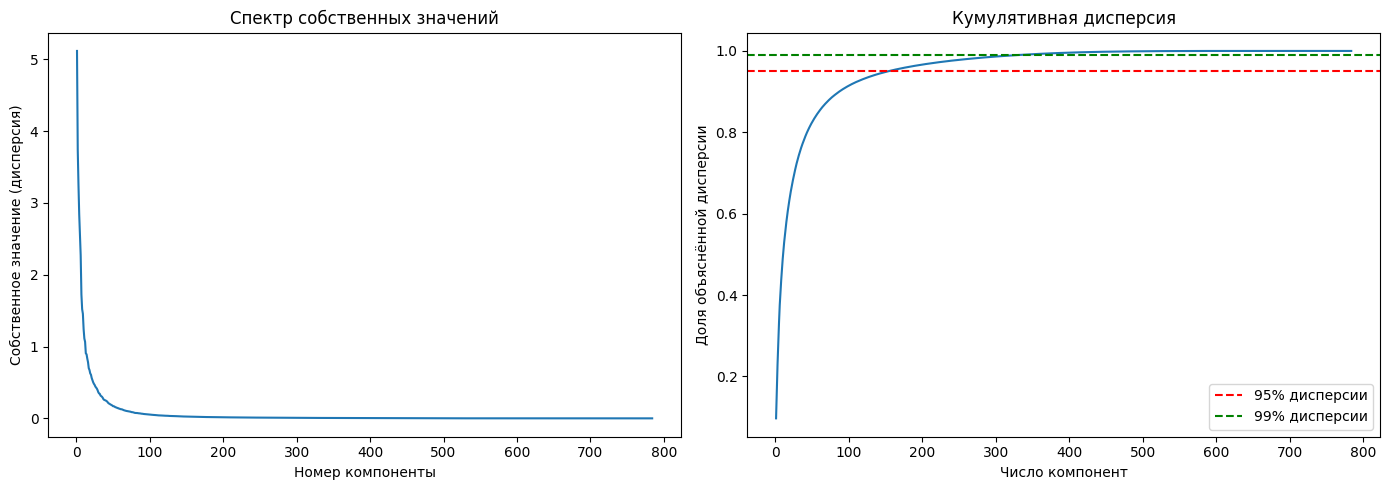

In [16]:
# PCA со всеми компонентами
pca_full = my_PCA()
pca_full.fit(X)

# Создаём два графика
fig, axes = plt.subplots(1,2,figsize=(14, 5))

# График 1: собственные значения
axes[0].plot(np.arange(1,len(pca_full.explained_variance_) + 1),pca_full.explained_variance_)
axes[0].set_xlabel('Номер компоненты')
axes[0].set_ylabel('Собственное значение (дисперсия)')
axes[0].set_title('Спектр собственных значений')

# Кумулятивная дисперсия
cumulative = np.cumsum(pca_full.explained_variance_)
cumulative /= cumulative[-1]

# График 2: кумулятивная дисперсия
axes[1].plot(np.arange(1, len(cumulative) + 1),cumulative)
axes[1].axhline(y=0.95,color='r',linestyle='--',label='95% дисперсии')
axes[1].axhline(y=0.99,color='g',linestyle='--',label='99% дисперсии')

axes[1].set_xlabel('Число компонент')
axes[1].set_ylabel('Доля объяснённой дисперсии')
axes[1].set_title('Кумулятивная дисперсия')
axes[1].legend()
plt.tight_layout()
plt.show()

In [17]:
print("Доля дисперсии первых 15 компонент:",cumulative[14])

Доля дисперсии первых 15 компонент: 0.57933766


In [18]:
n_99 = np.argmax(cumulative >= 0.99) + 1
print(f"Для 99% дисперсии нужно компонент: {n_99}")

Для 99% дисперсии нужно компонент: 331


#Как связаны собственные числа и дисперсия данных?
Собственное число в PCA показывает, насколько сильно данные разбросаны вдоль соответствующей главной компоненты. Большое собственное число означает большую дисперсию и более важную компоненту. Маленькое собственное число означает, что вдоль этого направления данные почти не меняются и такая компонента несёт мало информации.

часть 1.4

Форма Y_2d: (60000, 2)


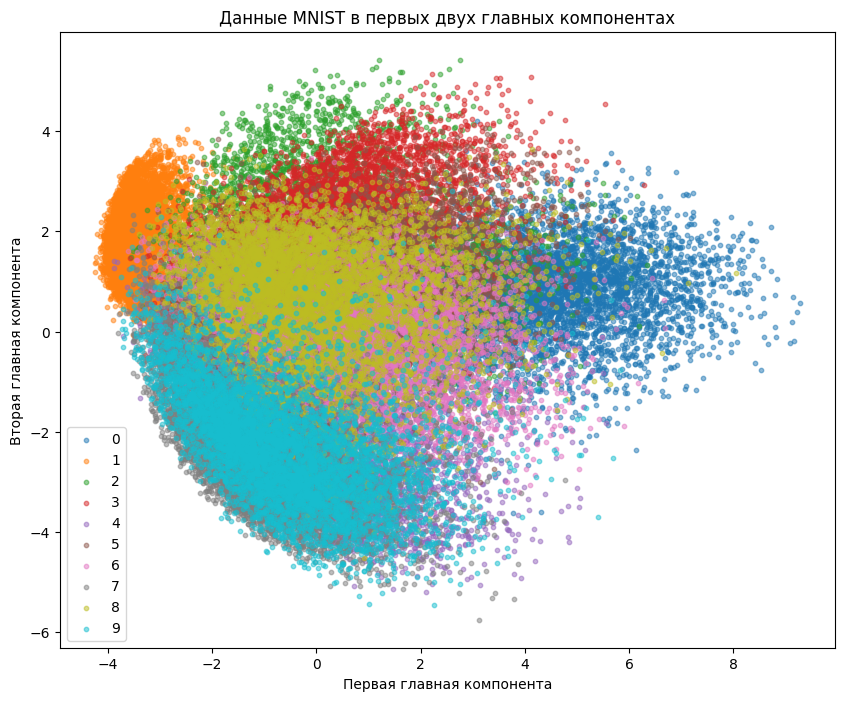

In [19]:
# PCA до двух компонент
pca_2d = my_PCA(n_components=2)

# Преобразуем данные
Y_2d = pca_2d.fit_transform(X)
print("Форма Y_2d:", Y_2d.shape)

# Строим график
plt.figure(figsize=(10, 8))

for digit in range(10):
  mask = (y == digit)
  plt.scatter(Y_2d[mask, 0],Y_2d[mask, 1],label=str(digit),alpha=0.5,s=10)

plt.xlabel('Первая главная компонента')
plt.ylabel('Вторая главная компонента')
plt.title('Данные MNIST в первых двух главных компонентах')
plt.legend()
plt.show()

На графике видно, что некоторые цифры образуют более выраженные группы: например, цифра 1 в основном располагается в левой верхней области, цифра 0 - справа,  а цифра 9 - в нижней части графика. При этом многие классы в центральной области сильно перекрываются. Это связано с тем, что PCA уменьшает размерность с 784 признаков до двух и при таком преобразовании большая часть информации теряется. Поэтому похожие изображения разных цифр могут иметь близкие координаты в пространстве первых двух главных компонент.

#Часть 2

часть 2.1

In [20]:
class my_kNN:
    def __init__(self, n_neighbors=5):
        self.n_neighbors = n_neighbors
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
        return self

    # Предсказание
    def predict(self, X):
        predictions = []
        for x in X:
            # Расстояния
            distances = np.sqrt(np.sum((self.X_train - x) ** 2,axis=1))

            # k ближайших
            nearest_indices = np.argsort(distances)[:self.n_neighbors]

            # Классы соседей
            nearest_labels = self.y_train[nearest_indices]

            # Самый частый класс
            prediction = np.argmax(np.bincount(nearest_labels))
            predictions.append(prediction)
        return np.array(predictions)

часть 2.2

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Разделим данные
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Уменьшаем выборки для быстрой проверки
X_train_small = X_train[:5000]
y_train_small = y_train[:5000]
X_test_small = X_test[:500]
y_test_small = y_test[:500]

# Обучаем свой kNN
my_knn = my_kNN(n_neighbors=5)
my_knn.fit(X_train_small, y_train_small)
y_pred_my = my_knn.predict(X_test_small)
accuracy_my = accuracy_score(y_test_small, y_pred_my)

print(f"Точность my_kNN: {accuracy_my:.4f}")

Точность my_kNN: 0.9260


точность my_kNN при k=5 составила 0.9260, то есть примерно 92.6%. Следовательно, реализация метода kNN хорошо распознаёт изображения из MNIST.

часть 2.3

In [28]:
from sklearn.neighbors import KNeighborsClassifier

# Обучите sklearn kNN
sk_knn = KNeighborsClassifier(n_neighbors=5)
sk_knn.fit(X_train, y_train)
y_pred_sk = sk_knn.predict(X_test)

accuracy_sk = accuracy_score(y_test, y_pred_sk)
print(f"Точность sklearn kNN: {accuracy_sk:.4f}")
print(f"Разница: {abs(accuracy_my - accuracy_sk):.4f}")

Точность sklearn kNN: 0.9668
Разница: 0.0258


часть 2.4

k = 1, Accuracy = 0.9280
k = 3, Accuracy = 0.9360
k = 5, Accuracy = 0.9260
k = 7, Accuracy = 0.9220
k = 10, Accuracy = 0.9280
k = 15, Accuracy = 0.9200
k = 20, Accuracy = 0.9040
k = 30, Accuracy = 0.8840


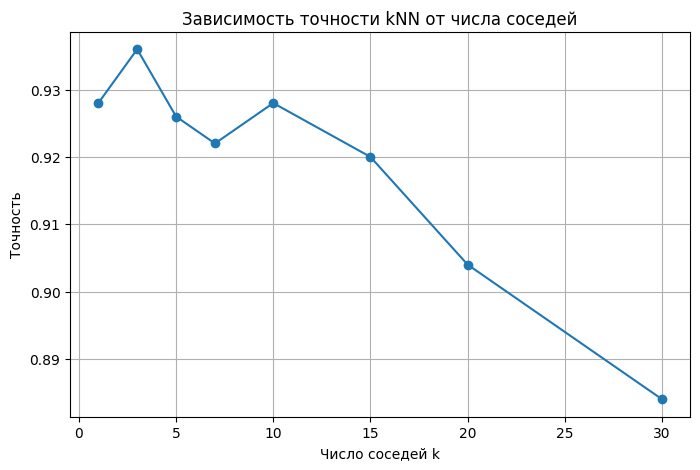

In [30]:
# Уменьшаем выборки для ускорения
X_train_small = X_train[:5000]
y_train_small = y_train[:5000]
X_test_small = X_test[:500]
y_test_small = y_test[:500]

# Проверяем разные k
k_values = [1, 3, 5, 7, 10, 15, 20, 30]
accuracies = []

for k in k_values:
  my_knn = my_kNN(n_neighbors=k)
  my_knn.fit(X_train_small, y_train_small)
  y_pred = my_knn.predict(X_test_small)
  accuracy = accuracy_score(y_test_small, y_pred)
  accuracies.append(accuracy)
  print(f"k = {k}, Accuracy = {accuracy:.4f}")

# График
plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, 'o-')
plt.xlabel('Число соседей k')
plt.ylabel('Точность')
plt.title('Зависимость точности kNN от числа соседей')
plt.grid(True)
plt.show()

In [31]:
best_index = np.argmax(accuracies)
best_k = k_values[best_index]

print(f"Лучшее k = {best_k}")
print(f"Максимальная Accuracy = {accuracies[best_index]:.4f}")

Лучшее k = 3
Максимальная Accuracy = 0.9360


**1. При каком k точность максимальна?**

В эксперименте максимальная точность достигается при k = 3 и составляет 0.9360 (93.6%). При дальнейшем увеличении числа соседей точность в целом снижается, хотя наблюдаются небольшие колебания.

**2. Почему при малых k точность может быть ниже?**

При маленьком числе соседей модель сильно зависит от отдельных ближайших объектов. Например, при k = 1 решение принимается только по одному соседу, который может оказаться нетипичным или иметь ошибку.

**3. Почему при слишком больших k точность снижается?**

При большом k модель учитывает не только самые близкие и похожие объекты, но и более далёкие изображения, которые могут уже принадлежать другим классам. В нашем эксперименте при k = 30 точность снизилась до 88.4%.


#Часть 3

часть 3.1

Компонент: 1, Accuracy: 0.2620
Компонент: 2, Accuracy: 0.4210
Компонент: 5, Accuracy: 0.7210
Компонент: 10, Accuracy: 0.8940
Компонент: 15, Accuracy: 0.9320
Компонент: 20, Accuracy: 0.9440
Компонент: 30, Accuracy: 0.9520
Компонент: 50, Accuracy: 0.9470
Компонент: 75, Accuracy: 0.9480
Компонент: 100, Accuracy: 0.9480
Компонент: 200, Accuracy: 0.9420
Компонент: 300, Accuracy: 0.9400
Компонент: 500, Accuracy: 0.9430
Компонент: 784, Accuracy: 0.9410


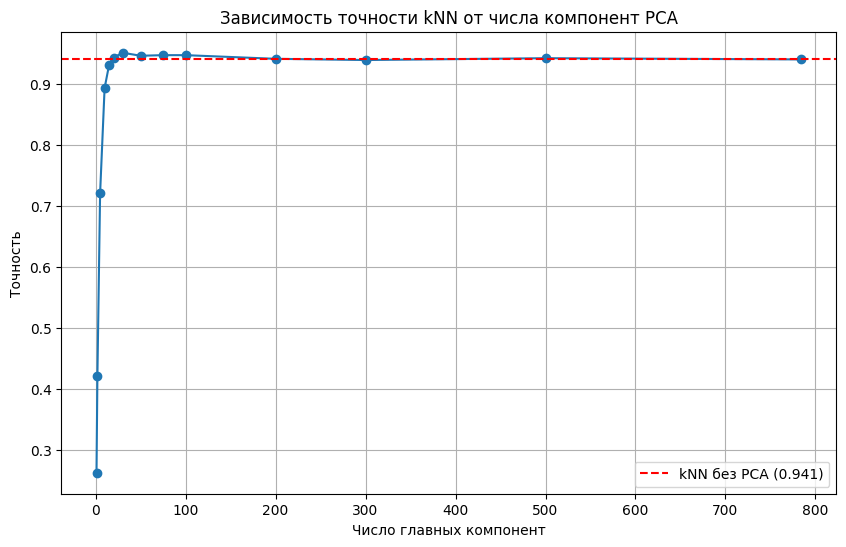

In [34]:
# Используем уменьшенные выборки
X_train_small = X_train[:10000]
y_train_small = y_train[:10000]
X_test_small = X_test[:1000]
y_test_small = y_test[:1000]

# Количество компонент
n_components_list = [1, 2, 5, 10, 15, 20, 30, 50, 75, 100, 200, 300, 500, 784]
accuracies_pca = []

# PCA со всеми компонентами
pca = my_PCA()
pca.fit(X_train_small)

# Преобразуем данные
Y_train = pca.transform(X_train_small)
Y_test = pca.transform(X_test_small)

# Проверяем разное количество компонент
for n_comp in n_components_list:
  X_train_pca = Y_train[:, :n_comp]
  X_test_pca = Y_test[:, :n_comp]

  #kNN
  knn = my_kNN(n_neighbors=5)
  knn.fit(X_train_pca, y_train_small)
  y_pred = knn.predict(X_test_pca)
  accuracy = accuracy_score(y_test_small, y_pred)
  accuracies_pca.append(accuracy)
  print(f"Компонент: {n_comp}, Accuracy: {accuracy:.4f}")

# Наш kNN без PCA
knn_full = my_kNN(n_neighbors=5)
knn_full.fit(X_train_small, y_train_small)
y_pred_full = knn_full.predict(X_test_small)
accuracy_full = accuracy_score(y_test_small, y_pred_full)

# График
plt.figure(figsize=(10, 6))
plt.plot(n_components_list, accuracies_pca, 'o-')
plt.axhline(y=accuracy_full,color='r',linestyle='--',label=f'kNN без PCA ({accuracy_full:.3f})')
plt.xlabel('Число главных компонент')
plt.ylabel('Точность')
plt.title('Зависимость точности kNN от числа компонент PCA')
plt.legend()
plt.grid(True)
plt.show()

**1. При каком числе компонент точность максимальна?**

Максимальная точность классификации достигается при **30 главных компонентах** и составляет **0.9520 (95.2%)**.

**2. Удалось ли превзойти точность kNN на всех 784 признаках?**

Да. Без PCA точность kNN составляет **0.9410 (94.1%)**, а при использовании 30 главных компонент увеличивается до **0.9520 (95.2%)**. Это значит, что PCA может не только уменьшить размерность данных, но и повысить качество классификации за счёт исключения некоторых избыточных или шумовых признаков.

**3. Что происходит при слишком малом числе компонент? Почему?**

При слишком малом количестве главных компонент точность значительно снижается. Например, при одной компоненте Accuracy составляет всего **26.2%**, при двух - **42.1%**, а при пяти - **72.1%**. Это происходит потому, что при сильном уменьшении размерности теряется много информации об изображениях, в том числе различия между цифрами.

часть 3.2

Компонент: 1, Время: 0.68 сек
Компонент: 2, Время: 0.92 сек
Компонент: 5, Время: 1.03 сек
Компонент: 10, Время: 1.15 сек
Компонент: 15, Время: 1.29 сек
Компонент: 20, Время: 1.35 сек
Компонент: 30, Время: 1.62 сек
Компонент: 50, Время: 2.05 сек
Компонент: 75, Время: 3.88 сек
Компонент: 100, Время: 3.33 сек
Компонент: 200, Время: 6.39 сек
Компонент: 300, Время: 9.31 сек
Компонент: 500, Время: 14.21 сек
Компонент: 784, Время: 19.06 сек


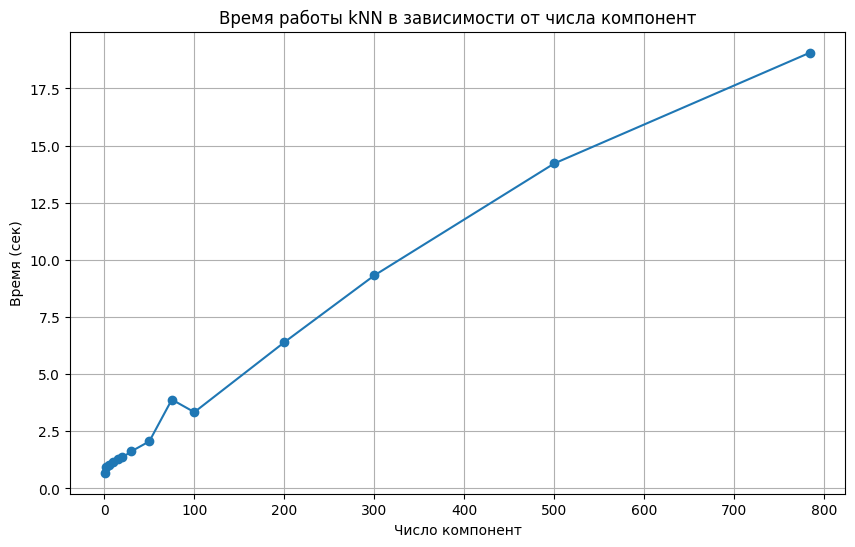

In [36]:
import time

# Время для разного числа компонент
times = []

for n_comp in n_components_list:
  # Берём нужное число компонент
  X_train_pca = Y_train[:, :n_comp]
  X_test_pca = Y_test[:, :n_comp]

  # Засекаем время
  start = time.time()

  # Наш kNN
  knn = my_kNN(n_neighbors=5)
  knn.fit(X_train_pca, y_train_small)
  y_pred = knn.predict(X_test_pca)

  # Вычисляем затраченное время
  elapsed = time.time() - start
  times.append(elapsed)
  print(f"Компонент: {n_comp}, Время: {elapsed:.2f} сек")

# Строим график
plt.figure(figsize=(10, 6))
plt.plot(n_components_list, times, 'o-')
plt.xlabel('Число компонент')
plt.ylabel('Время (сек)')
plt.title('Время работы kNN в зависимости от числа компонент')
plt.grid(True)
plt.show()

**Как изменяется время работы при уменьшении размерности? Объясните.**

При уменьшении количества главных компонент время работы kNN значительно сокращается. Это связано с тем, что алгоритм вычисляет евклидовы расстояния между объектами, и чем меньше признаков у каждого объекта, тем меньше вычислений требуется.

часть 3.3

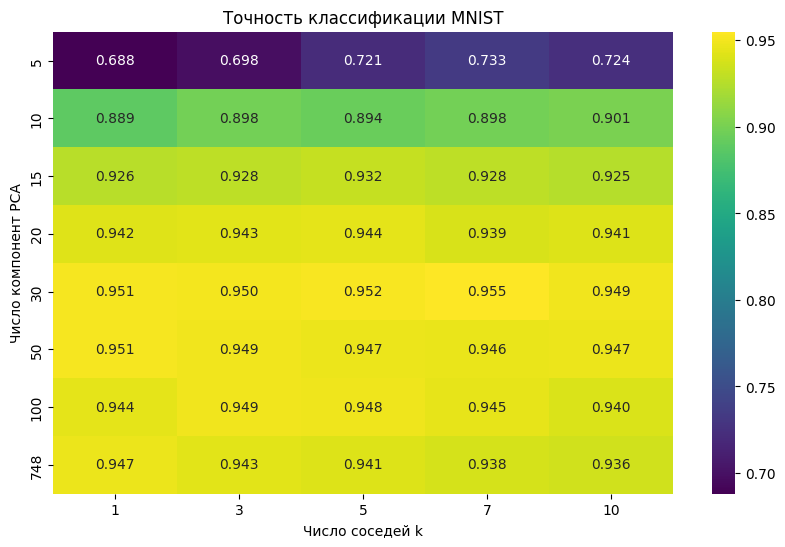

In [39]:
# Параметры
n_components_grid = [5, 10, 15, 20, 30, 50, 100, 748]
k_grid = [1, 3, 5, 7, 10]

# Матрица точности
accuracy_matrix = np.zeros((len(n_components_grid), len(k_grid)))

# Перебираем все комбинации
for i, n_comp in enumerate(n_components_grid):
  # Выбираем компоненты PCA
  X_train_pca = Y_train[:, :n_comp]
  X_test_pca = Y_test[:, :n_comp]

  for j, k in enumerate(k_grid):
    # Наш kNN
    knn = my_kNN(n_neighbors=k)
    knn.fit(X_train_pca, y_train_small)
    y_pred = knn.predict(X_test_pca)

    # Точность
    accuracy = accuracy_score(y_test_small, y_pred)
    accuracy_matrix[i, j] = accuracy

# Тепловая карта
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.heatmap(accuracy_matrix,annot=True,fmt='.3f',xticklabels=k_grid,yticklabels=n_components_grid,cmap='viridis')
plt.xlabel('Число соседей k')
plt.ylabel('Число компонент PCA')
plt.title('Точность классификации MNIST')
plt.show()

**1. Какая комбинация параметров даёт наилучшую точность?**

Наибольшая точность классификации достигается при **30 главных компонентах PCA и числе соседей k = 7**. Точность составляет **0.955 (95.5%)**. Это показывает, что для хорошего распознавания цифр из MNIST необязательно использовать все 784 исходных признака, достаточно сохранить наиболее информативные главные компоненты.

**2. Какая комбинация даёт наихудшую точность?**

Наихудший результат получен при **5 главных компонентах и k = 1**. Точность составляет **0.688 (68.8%)**. Это связано с тем, что при уменьшении размерности до пяти компонент теряется значительная часть информации об изображениях. Кроме того, при k = 1 классификация зависит только от одного ближайшего соседа, поэтому модель становится более чувствительной к шуму и отдельным нетипичным объектам.

**3. Есть ли комбинации, где точность выше, чем у kNN на полных данных? Что это говорит о PCA?**

Да, несколько комбинаций параметров показали точность выше, чем kNN без PCA. При k = 7  на всех 784 признаках точность составляет **0.938 (93.8%)**, а при 30 компонентах и k = 7 она увеличилась до **0.955 (95.5%)**.

Таким образом, PCA позволяет значительно уменьшить количество признаков и при этом сохранить или даже повысить точность классификации. Это  связано с тем, что PCA устраняет часть избыточной информации. Но слишком сильное уменьшение размерности приводит к потере полезной информации и снижению точности.

#Часть 4

### Вывод

В данной лабораторной работе были изучены и реализованы методы PCA и kNN для распознавания рукописных цифр MNIST.

**PCA (метод главных компонент)** используется для уменьшения размерности данных: он находит направления максимальной дисперсии и позволяет сохранить наиболее значимую часть информации с меньшим количеством признаков.

**kNN (метод k-ближайших соседей)** определяет класс нового объекта по большинству классов его ближайших соседей. Его преимуществами являются простота реализации и отсутствие сложного обучения, а недостатками - медленная классификация на больших выборках и чувствительность к шуму и размерности.

Эксперименты показали, что применение PCA перед kNN может не только ускорить классификацию, но и повысить её точность.

Наилучший результат в нашем эксперименте был получен при **30 главных компонентах и k = 7**, где Accuracy составила **95,5%**, тогда как kNN без PCA при k = 5 показал **94,1%**.

Таким образом, среди проверенных вариантов оптимальной размерностью оказалось **30 компонент вместо 784**, поскольку они позволили сохранить достаточно информации для распознавания цифр, а дальнейшее увеличение размерности не улучшило максимальную точность.

Также уменьшение размерности значительно сокращает время вычисления расстояний между объектами.

Самым сложным этапом работы оказались реализация алгоритма PCA.

Самым интересным был результат того, что уменьшение числа признаков почти в 25 раз позволило получить более высокую точность классификации и ускорить работу kNN.